# #40 — Single-Cell Multiomics: Joint RNA + Surface Protein (CITE-seq)

Real 10x Genomics CITE-seq dataset: **`pbmc_10k_protein_v3`** — 7,865 real PBMCs from a healthy donor,
each with both a real mRNA profile (21,015 genes) and a real surface-protein profile (17-antibody
TotalSeq-B panel: 14 real target markers + 3 real isotype controls).

**The real question:** does jointly modeling both real modalities (via totalVI, a real published deep
generative model for CITE-seq) find anything RNA alone wouldn't -- and how well does the real surface-
protein signal actually agree with its corresponding RNA genes?

Read `PROJECT_NARRATIVE.md` and `WORKFLOW.md` before starting. Docs to look up as you go:
scanpy (`https://scanpy.readthedocs.io`), scvi-tools / totalVI (`https://docs.scvi-tools.org`).


## Step 0 — Fetch the real data and set up

**Real file, real source, downloaded ONCE on your own machine** (this teaching environment's sandbox has
restricted outbound network access to most bioinformatics hosts -- confirmed directly during this
project's build; only PyPI was reliably reachable). Run this on your own machine / Kaggle / Colab:

```bash
mkdir -p data
curl -L -o data/pbmc_10k_protein_v3_filtered_feature_bc_matrix.h5 \
  https://cf.10xgenomics.com/samples/cell-exp/3.0.0/pbmc_10k_protein_v3/pbmc_10k_protein_v3_filtered_feature_bc_matrix.h5
```

This is Cell Ranger 3.0.0's own real combined output: both the real "Gene Expression" and real "Antibody
Capture" feature types, indexed by the same real cell barcodes, in one `.h5` file.


In [1]:
pip install scanpy scvi-tools leidenalg igraph muon --quiet

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [2]:
!mkdir -p data
!curl -L -o data/pbmc_10k_protein_v3_filtered_feature_bc_matrix.h5 https://cf.10xgenomics.com/samples/cell-exp/3.0.0/pbmc_10k_protein_v3/pbmc_10k_protein_v3_filtered_feature_bc_matrix.h5
!ls -la data/

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 20.7M  100 20.7M    0     0  90.9M      0 --:--:-- --:--:-- --:--:-- 91.1M
total 21288
drwxr-xr-x 2 root root     4096 Oct 25 11:17 .
drwxr-xr-x 4 root root     4096 Oct 25 11:17 ..
-rw-r--r-- 1 root root 21788278 Oct 25 11:17 pbmc_10k_protein_v3_filtered_feature_bc_matrix.h5


In [3]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
from sklearn.metrics import adjusted_rand_score
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

sc.settings.verbosity = 1

# GIVEN: load the real combined matrix. gex_only=False keeps BOTH real feature types in one AnnData.
adata_combined = sc.read_10x_h5("data/pbmc_10k_protein_v3_filtered_feature_bc_matrix.h5", gex_only=False)
adata_combined.var_names_make_unique()
print(adata_combined)
print(adata_combined.var["feature_types"].value_counts())


AnnData object with n_obs × n_vars = 7865 × 33555
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence'
    layers: None (.X)
feature_types
Gene Expression     33538
Antibody Capture       17
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:322: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  return AnnData(matrix, obs=obs_dict, var=var_dict)


## Step 1 — Split into the two real modalities

**WHAT·WHY·HOW:** `adata_combined.var['feature_types']` tells you, for every column, whether it's a real
gene ("Gene Expression") or a real antibody ("Antibody Capture") -- the exact same combined-matrix
structure Cell Ranger always produces for CITE-seq. Build a boolean mask for each, then subset the
AnnData's **columns** (genes/antibodies are columns; cells are rows) to get two separate, real AnnData
objects that still share the same real cell barcodes (rows) and can be lined up 1:1.


In [4]:
is_gex = adata_combined.var["feature_types"] == "Gene Expression"
is_adt = adata_combined.var["feature_types"] == "Antibody Capture"

rna = adata_combined[:, is_gex].copy()
prot = adata_combined[:, is_adt].copy()

print("RNA:", rna.shape, " | Protein:", prot.shape)
assert prot.shape[1] == 17, "the real TotalSeq-B panel for this dataset has 17 antibodies -- check your mask"


RNA: (7865, 33538)  | Protein: (7865, 17)


## Step 2 — QC each modality on its own real terms

**WHAT·WHY·HOW (biology):** RNA QC is the same as #4's: real total counts, real genes detected, real
mitochondrial fraction (dying/stressed cells leak nuclear mRNA faster than mito mRNA, so a high mito % is a
real low-quality-cell signal). Protein QC is different: there's no "mitochondrial protein" equivalent, but
this real panel ships its own real background reference -- 3 isotype-control antibodies (IgG1, IgG2a,
IgG2b) that target nothing real in human cells, so their real signal in each cell is an estimate of that
cell's real non-specific antibody background.


In [5]:
# RNA QC (same real approach as project #4)
rna.var["mt"] = rna.var_names.str.startswith("MT-")   # real human mito gene prefix
sc.pp.calculate_qc_metrics(rna, qc_vars=['mt'], inplace=True)

# Protein QC: split the real 17-antibody panel into real targets vs real isotype controls
isotypes = ["IgG2a_control_TotalSeqB", "IgG1_control_TotalSeqB", "IgG2b_control_TotalSeqB"]   # "IgG1", "IgG2a", "IgG2b" -- the real 3 isotype controls in this panel
targets = [p for p in prot.var_names if p not in isotypes]
print(f"real targets: {len(targets)}, real isotype controls: {len(isotypes)}")

prot.obs["isotype_signal"] = np.asarray(prot[:, isotypes].X.sum(axis=1)).ravel()
prot.obs["target_signal"] = np.asarray(prot[:, targets].X.sum(axis=1)).ravel()

# Real sanity check: mean per-antibody isotype signal should be LOWER than mean per-antibody target signal
mean_isotype_per_ab = prot.obs["isotype_signal"].mean() / len(isotypes)
mean_target_per_ab = prot.obs["target_signal"].mean() / len(targets)
print(f"mean real signal per antibody -- isotype: {mean_isotype_per_ab:.2f}, target: {mean_target_per_ab:.2f}")


real targets: 14, real isotype controls: 3
mean real signal per antibody -- isotype: 9.14, target: 462.98


## Step 3 — Filter cells using the real measured distributions

**WHAT·WHY·HOW:** Never hardcode a QC threshold you haven't actually looked at. Plot the real
distributions first (histograms of `total_counts`, `n_genes_by_counts`, `pct_counts_mt` for RNA; of
`isotype_signal` for protein), THEN pick thresholds that match what you actually see -- a real low-quality
tail to cut, not a number copied from a tutorial on different data.


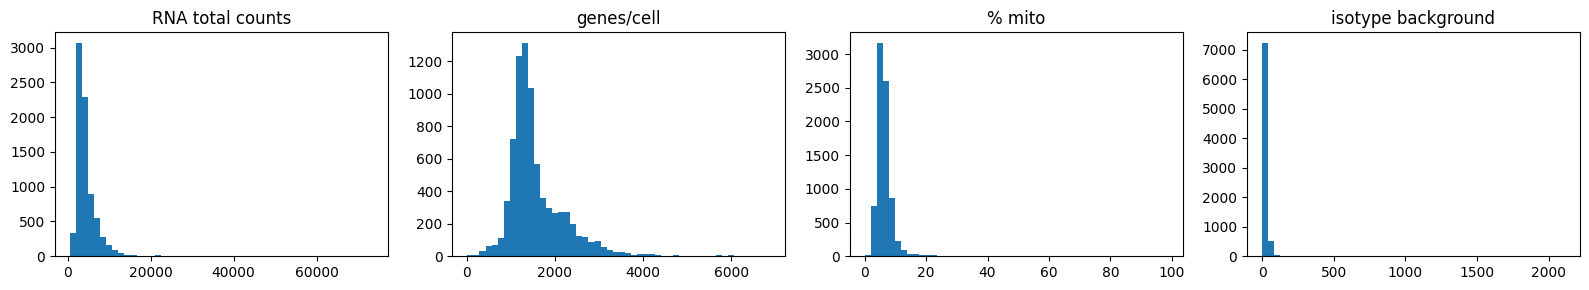

In [6]:
import os
os.makedirs("results", exist_ok=True)

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
axes[0].hist(rna.obs["total_counts"], bins=50); axes[0].set_title("RNA total counts")
axes[1].hist(rna.obs["n_genes_by_counts"], bins=50); axes[1].set_title("genes/cell")
axes[2].hist(rna.obs["pct_counts_mt"], bins=50); axes[2].set_title("% mito")
axes[3].hist(prot.obs["isotype_signal"], bins=50); axes[3].set_title("isotype background")
plt.tight_layout(); plt.savefig("results/qc_distributions.png", dpi=120)
plt.show()


In [7]:
# WRITE-IT: set real thresholds based on what you just saw in the plots above -- state your real reasoning
# in a markdown note once you've looked (e.g. "cut at pct_counts_mt > X because the real tail starts there")
min_genes = 200     # look at your histogram, e.g. 200
max_pct_mt = 20     # look at your histogram, e.g. 15 (percent, not fraction)

keep = (rna.obs["n_genes_by_counts"] >= min_genes) & (rna.obs["pct_counts_mt"] <= max_pct_mt)
print(f"keeping {keep.sum()} / {len(keep)} real cells")

rna = rna[keep].copy()
prot = prot[keep].copy()
assert rna.shape[0] == prot.shape[0], "RNA and protein must stay aligned on the same real cells"


keeping 7798 / 7865 real cells


## Step 4 — RNA-only clustering (the real baseline, same method as #4)

**WHAT·WHY·HOW:** Build the RNA-only cell-type structure first, with exactly the method #4 already used
(normalize, log1p, PCA, neighbors, Leiden, UMAP) -- this is the real baseline the joint (totalVI) result
gets compared against later. Keep a raw-counts copy before normalizing: totalVI needs real raw integer
counts, not log-normalized values.


resolution=0.3: 12 clusters
resolution=0.5: 13 clusters
resolution=0.8: 16 clusters
resolution=1.0: 20 clusters


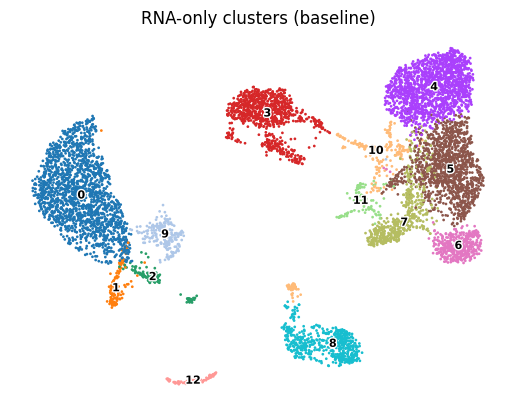

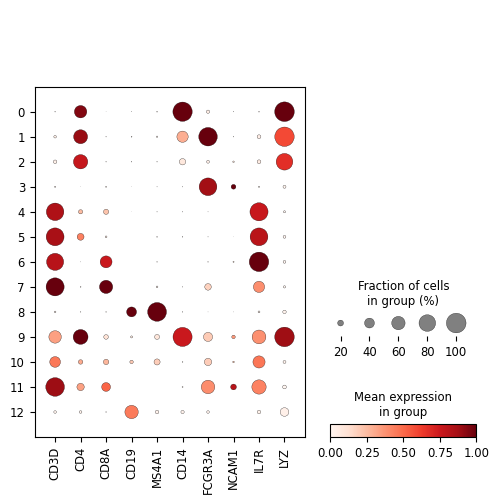

In [8]:
rna.layers["counts"] = rna.X.copy()   # keep the real raw counts for totalVI later

sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
sc.pp.pca(rna, n_comps=20)
sc.pp.neighbors(rna, use_rep="X_pca")

# scan a few resolutions first -- don't guess, measure
for res in [0.3, 0.5, 0.8, 1.0]:
    sc.tl.leiden(rna, key_added=f"leiden_test_{res}", flavor="igraph", n_iterations=2, resolution=res)
    print(f"resolution={res}: {rna.obs[f'leiden_test_{res}'].nunique()} clusters")

# pick whichever resolution above landed closest to ~6-10 real PBMC cell types
chosen_resolution = 0.5   # <-- change this to match what your own scan above actually showed

sc.tl.leiden(rna, key_added="leiden_rna_only", flavor="igraph", n_iterations=2, resolution=chosen_resolution)
sc.tl.umap(rna)

sc.pl.umap(rna, color="leiden_rna_only", legend_loc="on data", legend_fontsize=8,
           legend_fontoutline=2, title="RNA-only clusters (baseline)", frameon=False) 

canonical_markers = ["CD3D", "CD4", "CD8A", "CD19", "MS4A1", "CD14", "FCGR3A", "NCAM1", "IL7R", "LYZ"]
canonical_markers = [g for g in canonical_markers if g in rna.var_names]

sc.pl.dotplot(rna, var_names=canonical_markers, groupby="leiden_rna_only", standard_scale="var")

## Step 5 — Fit totalVI: the real joint RNA+protein model

**WHAT·WHY·HOW (math -> code):** totalVI needs the real raw protein counts sitting in `.obsm` on the
*RNA* AnnData (its real documented API registers one modality's raw counts in `.obsm`, keyed by name), and
the real raw RNA counts in a layer. Fitting it gives, per real cell: a joint latent coordinate, and a
model-based denoised (background-corrected) protein estimate -- see PROJECT_NARRATIVE.md Section 4 for the
full real math. Install once: `pip install scvi-tools`.


In [13]:
import scvi

In [14]:
sc.pp.highly_variable_genes(rna, n_top_genes=4000, flavor="seurat_v3", layer="counts")
rna_hvg = rna[:, rna.var.highly_variable].copy()
print(rna_hvg.shape)

(7798, 4000)


In [15]:
rna.obsm["protein_expression"] = pd.DataFrame(
    prot.X.toarray() if hasattr(prot.X, "toarray") else prot.X,
    index=rna.obs_names, columns=prot.var_names
)
rna_hvg.obsm["protein_expression"] = rna.obsm["protein_expression"]

scvi.model.TOTALVI.setup_anndata(rna_hvg, layer="counts", protein_expression_obsm_key="protein_expression")
vae = scvi.model.TOTALVI(rna_hvg)
vae.train()

rna.obsm["X_totalVI"] = vae.get_latent_representation(rna_hvg)
rna_denoised, protein_denoised = vae.get_normalized_expression(rna_hvg, n_samples=10, return_mean=True)
prot.layers["denoised"] = protein_denoised.values

INFO     Using column names from columns of adata.obsm['protein_expression']                                       


ERROR:tornado.application:Exception in callback functools.partial(<bound method OutStream._flush of <ipykernel.iostream.OutStream object at 0x7bb755ccf850>>)
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
  File "/usr/local/lib/python3.13/dist-packages/ipykernel/iostream.py", line 518, in _flush
    self.session.send(
    ~~~~~~~~~~~~~~~~~^
        self.pub_thread,
        ^^^^^^^^^^^^^^^^
    ...<3 lines>...
        ident=self.topic,
        ^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 820, in send
    msg = self.msg(
        msg_or_type,
    ...<3 lines>...
        metadata=metadata,
    )
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 661, in msg
    header = self.msg_header(msg_type) if header is None else header
             ~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/usr/local/lib/python3

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 45 records. Best score: 1372.405. Signaling Trainer to stop.


## Step 6 — Joint clusters from the real totalVI latent space

**WHAT·WHY·HOW:** Exactly the same clustering recipe as Step 4, but built on `X_totalVI` instead of
`X_pca` -- the real joint representation now carries real information from BOTH modalities.


resolution=0.3: 12 clusters
resolution=0.5: 15 clusters
resolution=0.8: 17 clusters
resolution=1.0: 21 clusters


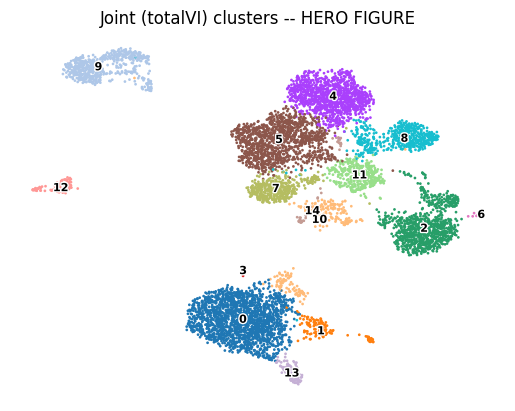

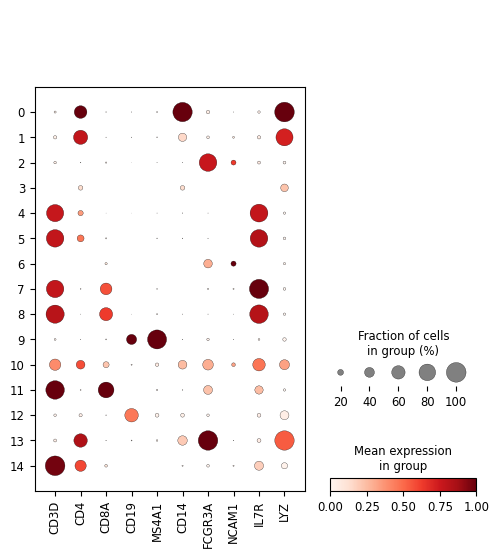

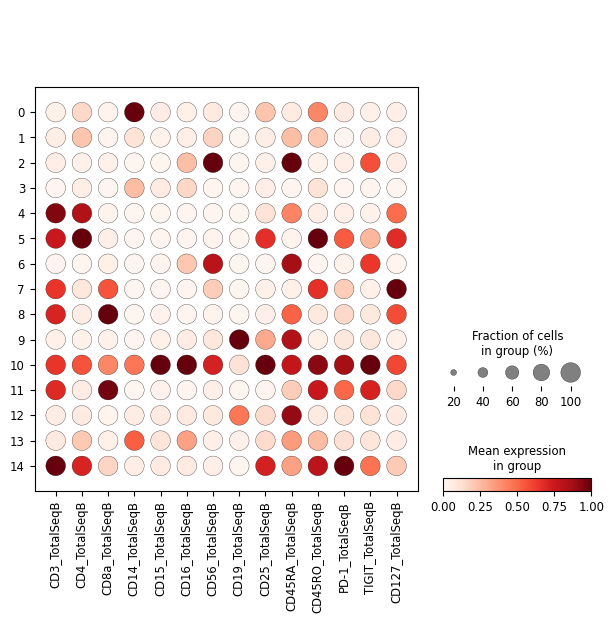

In [19]:
sc.pp.neighbors(rna, use_rep="X_totalVI", key_added="joint")

for res in [0.3, 0.5, 0.8, 1.0]:
    sc.tl.leiden(rna, neighbors_key="joint", key_added=f"leiden_joint_test_{res}", flavor="igraph", n_iterations=2, resolution=res)
    print(f"resolution={res}: {rna.obs[f'leiden_joint_test_{res}'].nunique()} clusters")

chosen_resolution_joint = 0.5   # change to match your own scan's output

sc.tl.leiden(rna, neighbors_key="joint", key_added="leiden_joint", flavor="igraph", n_iterations=2, resolution=chosen_resolution_joint)
sc.tl.umap(rna, neighbors_key="joint")

sc.pl.umap(rna, color="leiden_joint", legend_loc="on data", legend_fontsize=8,
           legend_fontoutline=2, title="Joint (totalVI) clusters -- HERO FIGURE", frameon=False)

# RNA markers per joint cluster
canonical_markers = ["CD3D", "CD4", "CD8A", "CD19", "MS4A1", "CD14", "FCGR3A", "NCAM1", "IL7R", "LYZ"]
canonical_markers = [g for g in canonical_markers if g in rna.var_names]
sc.pl.dotplot(rna, var_names=canonical_markers, groupby="leiden_joint", standard_scale="var")

# real denoised protein markers per joint cluster -- the whole point of the joint model
prot.obs["leiden_joint"] = rna.obs["leiden_joint"].values
sc.pl.dotplot(prot, var_names=targets, groupby="leiden_joint", standard_scale="var", layer="denoised")

## Step 7 — Does real protein agree with its real RNA gene?

**WHAT·WHY·HOW (biology):** For each of the real canonical markers in this panel, correlate the real
denoised protein level against its real corresponding RNA gene, across all real cells. Real gene-to-
antibody map for this exact panel (note: CD45RA and CD45RO are real splice isoforms of the SAME gene,
`PTPRC` -- RNA-level correlation can't tell them apart, a real, worth-disclosing limitation, not a bug):

```
CD3->CD3D, CD4->CD4, CD8a->CD8A, CD14->CD14, CD15->FUT4, CD16->FCGR3A, CD56->NCAM1,
CD19->CD19, CD25->IL2RA, CD45RA->PTPRC, CD45RO->PTPRC, PD-1->PDCD1, TIGIT->TIGIT, CD127->IL7R
```


In [23]:
gene_map = {"CD3_TotalSeqB": "CD3D", "CD4_TotalSeqB": "CD4", "CD8a_TotalSeqB": "CD8A",
            "CD14_TotalSeqB": "CD14", "CD15_TotalSeqB": "FUT4", "CD16_TotalSeqB": "FCGR3A",
            "CD56_TotalSeqB": "NCAM1", "CD19_TotalSeqB": "CD19", "CD25_TotalSeqB": "IL2RA",
            "CD45RA_TotalSeqB": "PTPRC", "CD45RO_TotalSeqB": "PTPRC", "PD-1_TotalSeqB": "PDCD1",
            "TIGIT_TotalSeqB": "TIGIT", "CD127_TotalSeqB": "IL7R"}

rows = []
for ab, gene in gene_map.items():
    if gene not in rna.var_names:
        continue
    protein_vals = prot[:, ab].layers["denoised"].ravel()
    gene_vals = rna[:, gene].X.toarray().ravel()
    r, p = pearsonr(protein_vals, gene_vals)
    rows.append((ab, gene, r, p))

corr_df = pd.DataFrame(rows, columns=["antibody", "gene", "pearson_r", "p_value"])
corr_df.to_csv("results/rna_protein_correlation.csv", index=False)
corr_df.sort_values("pearson_r", ascending=False)

,antibody,gene,pearson_r,p_value
3,CD14_TotalSeqB,CD14,0.899855,0.000000e+00
13,CD127_TotalSeqB,IL7R,0.838922,0.000000e+00
0,CD3_TotalSeqB,CD3D,0.765024,0.000000e+00
2,CD8a_TotalSeqB,CD8A,0.759746,0.000000e+00
7,CD19_TotalSeqB,CD19,0.596589,0.000000e+00
5,CD16_TotalSeqB,FCGR3A,0.379022,6.855748e-265
12,TIGIT_TotalSeqB,TIGIT,0.372508,3.117782e-255
6,CD56_TotalSeqB,NCAM1,0.348541,1.428930e-221
8,CD25_TotalSeqB,IL2RA,0.278770,3.619521e-139
10,CD45RO_TotalSeqB,PTPRC,0.193320,1.544153e-66


## Step 8 — Does the joint model actually change anything vs RNA-only?

**WHAT·WHY·HOW:** The project's central, honest question. Compare `leiden_rna_only` against
`leiden_joint` on the exact same real cells with the Adjusted Rand Index (1.0 = identical partitions,
~0.0 = no better than random agreement) and a contingency table (which RNA-only clusters got split/merged
differently once protein was added).


In [24]:
ari = adjusted_rand_score(rna.obs["leiden_rna_only"], rna.obs["leiden_joint"])   # adjusted_rand_score(...)
print(f"ARI, RNA-only vs joint: {ari:.3f}")

contingency = pd.crosstab(rna.obs["leiden_rna_only"], rna.obs["leiden_joint"])   # pd.crosstab(...)
contingency.to_csv("results/rna_only_vs_joint_contingency.csv")
contingency


ARI, RNA-only vs joint: 0.795


leiden_joint,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
leiden_rna_only,,,,,,,,,,,,,,,
0,1749,18,0,1,0,0,0,0,0,0,5,0,0,2,0
1,25,0,0,0,0,0,0,0,0,0,0,0,0,109,0
2,0,117,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,879,0,0,0,4,0,1,0,33,2,0,0,0
4,0,0,0,0,1111,26,0,1,397,0,7,0,0,0,0
5,0,0,9,0,53,1108,0,27,27,0,2,9,0,0,15
6,0,0,1,0,0,10,0,389,0,0,7,0,0,0,0
7,0,0,0,0,3,23,0,21,115,0,8,307,0,0,0
8,0,0,8,0,0,0,0,0,1,546,4,0,0,0,0


## Step 9 — Export real results


In [26]:
import os
os.makedirs("results", exist_ok=True)

rna.obs[["leiden_rna_only", "leiden_joint"]].to_csv("results/joint_cell_annotations.csv")
pd.DataFrame({"ari_rna_only_vs_joint": [ari]}).to_csv("results/rna_only_vs_joint_ari.csv", index=False)

print("Done. Real results written to results/.")


Done. Real results written to results/.
